# PlantSeg Dataset EDA

This notebook explores PlantSeg, an in-the-wild plant disease segmentation dataset with image-level LabelMe polygon annotations. It focuses on dataset integrity, annotation coverage, disease-label composition, image geometry, lesion/foreground coverage, and qualitative image-mask overlays.

PlantSeg is distributed through [Zenodo](https://doi.org/10.5281/zenodo.17719108). Download the archive separately and extract it under `data/raw/plantseg/` or `data/PlantSeg/`; raw images are not committed to this repository.

In [1]:
from pathlib import Path
import json
import math
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CANDIDATE_DIRS = [ROOT / 'data' / 'raw' / 'plantseg', ROOT / 'data' / 'raw' / 'PlantSeg', ROOT / 'data' / 'PlantSeg']
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
JSON_EXTENSIONS = {'.json'}
DATA_DIR = next((path for path in CANDIDATE_DIRS if path.exists()), CANDIDATE_DIRS[0])
print(f'Project root: {ROOT.resolve()}')
print(f'PlantSeg directory: {DATA_DIR.resolve()}')
if not DATA_DIR.exists():
    print('PlantSeg data was not found. Download from https://doi.org/10.5281/zenodo.17719108 and extract it into data/raw/plantseg/.')


Project root: /home/idrislabidi/vscode/plant-disease-project
PlantSeg directory: /home/idrislabidi/vscode/plant-disease-project/data/raw/plantseg


## 1. Inventory files and pair images with annotations

In [3]:
image_paths = sorted(path for path in (DATA_DIR / 'images').rglob('*') if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS)
mask_paths = sorted(path for path in (DATA_DIR / 'annotations').rglob('*') if path.is_file() and path.suffix.lower() in {'.png', '.jpg', '.jpeg'})
manifest_paths = sorted(DATA_DIR.glob('annotation_*.json'))
image_by_stem = {}
for path in image_paths:
    image_by_stem.setdefault(path.stem.lower(), []).append(path)
mask_by_stem = {}
for path in mask_paths:
    mask_by_stem.setdefault(path.stem.lower(), []).append(path)
paired = [(path, mask_by_stem.get(path.stem.lower(), [None])[0]) for path in image_paths]
orphan_masks = [path for stem, paths in mask_by_stem.items() if stem not in image_by_stem for path in paths]
duplicate_image_stems = {stem: paths for stem, paths in image_by_stem.items() if len(paths) > 1}
print(f'Images: {len(image_paths):,}')
print(f'Pixel-mask files: {len(mask_paths):,}')
print(f'COCO-style manifests: {len(manifest_paths):,}')
print(f'Images with a same-stem mask: {sum(mask is not None for _, mask in paired):,}')
print(f'Images without a same-stem mask: {sum(mask is None for _, mask in paired):,}')
print(f'Orphan masks: {len(orphan_masks):,}')
print(f'Duplicate image stems: {len(duplicate_image_stems):,}')
if not image_paths:
    raise FileNotFoundError('No PlantSeg images found. Extract the Zenodo download under data/raw/plantseg/ and rerun this cell.')

Images: 7,774
Pixel-mask files: 7,774
COCO-style manifests: 3
Images with a same-stem mask: 7,774
Images without a same-stem mask: 0
Orphan masks: 0
Duplicate image stems: 0


## 2. Parse LabelMe polygons and build an image-level table

In [5]:
metadata_table = pd.read_csv(DATA_DIR / 'Metadata.csv')
metadata_by_name = metadata_table.set_index('Name')

records = []
unreadable_images = []
invalid_annotations = []
for image_path, mask_path in paired:
    try:
        with Image.open(image_path) as image:
            width, height = image.size
            mode = image.mode
        mask = np.asarray(Image.open(mask_path).convert('L')) if mask_path is not None else np.zeros((height, width), dtype=np.uint8)
        foreground = mask > 0
        row_indices, column_indices = np.where(foreground)
        annotated_area = float(foreground.sum())
        bbox_width = float(column_indices.max() - column_indices.min() + 1) if len(column_indices) else 0.0
        bbox_height = float(row_indices.max() - row_indices.min() + 1) if len(row_indices) else 0.0
        metadata = metadata_by_name.loc[image_path.name] if image_path.name in metadata_by_name.index else None
        labels = [str(metadata['Disease'])] if metadata is not None else ['unknown']
        split = str(metadata['Split']) if metadata is not None else 'unknown'
    except Exception as error:
        if mask_path is None:
            invalid_annotations.append((image_path, str(error)))
        else:
            unreadable_images.append((image_path, str(error)))
        continue
    records.append({'image_path': image_path, 'annotation_path': mask_path, 'width': width, 'height': height, 'mode': mode, 'labels': labels, 'split': split, 'polygon_count': len(labels), 'annotated_area': annotated_area, 'bbox_width': bbox_width, 'bbox_height': bbox_height})

df = pd.DataFrame(records)
df['image_area'] = df['width'] * df['height']
df['foreground_ratio'] = (df['annotated_area'] / df['image_area']).clip(0, 1)
df['aspect_ratio'] = df['width'] / df['height']
df['labels_display'] = df['labels'].map(lambda labels: ', '.join(labels) if labels else '(no labels)')
print(f'Readable image-mask pairs: {len(df):,}')
print(f'Unreadable images: {len(unreadable_images):,}')
print(f'Invalid image/mask pairs: {len(invalid_annotations):,}')
print(f'Metadata rows matched: {df["labels_display"].ne("unknown").sum():,}')
display(df.head())

Readable image-mask pairs: 7,774
Unreadable images: 0
Invalid image/mask pairs: 0
Metadata rows matched: 7,774


,image_path,annotation_path,width,height,mode,labels,split,polygon_count,annotated_area,bbox_width,bbox_height,image_area,foreground_ratio,aspect_ratio,labels_display
0,/home/idrislabidi/vscode/plant-disease-project...,/home/idrislabidi/vscode/plant-disease-project...,268,172,RGB,[apple black rot],Test,1,10742.0,132.0,147.0,46096,0.233035,1.558140,apple black rot
1,/home/idrislabidi/vscode/plant-disease-project...,/home/idrislabidi/vscode/plant-disease-project...,293,220,RGB,[apple black rot],Test,1,13807.0,135.0,132.0,64460,0.214195,1.331818,apple black rot
2,/home/idrislabidi/vscode/plant-disease-project...,/home/idrislabidi/vscode/plant-disease-project...,300,287,RGB,[apple black rot],Test,1,42521.0,237.0,232.0,86100,0.493856,1.045296,apple black rot
3,/home/idrislabidi/vscode/plant-disease-project...,/home/idrislabidi/vscode/plant-disease-project...,400,300,RGB,[apple black rot],Test,1,26220.0,226.0,213.0,120000,0.218500,1.333333,apple black rot
4,/home/idrislabidi/vscode/plant-disease-project...,/home/idrislabidi/vscode/plant-disease-project...,450,300,RGB,[apple black rot],Test,1,10933.0,172.0,96.0,135000,0.080985,1.500000,apple black rot


## 3. Annotation quality and label composition

In [6]:
label_counts = Counter(label for labels in df['labels'] for label in labels)
label_table = pd.Series(label_counts, name='polygon_count').sort_values(ascending=False).to_frame()
label_table['image_count'] = [sum(label in labels for labels in df['labels']) for label in label_table.index]
summary = pd.Series({
    'images': len(df),
    'images_with_annotations': int(df['annotation_path'].notna().sum()),
    'images_with_polygons': int((df['polygon_count'] > 0).sum()),
    'total_polygons': int(df['polygon_count'].sum()),
    'unique_labels': len(label_counts),
    'median_foreground_ratio': df['foreground_ratio'].median(),
})
display(summary.to_frame('value'))
display(label_table.head(30))


,value
images,7774.000000
images_with_annotations,7774.000000
images_with_polygons,7774.000000
total_polygons,7774.000000
unique_labels,115.000000
median_foreground_ratio,0.138604


,polygon_count,image_count
citrus canker,323,323
wheat head scab,230,230
wheat stripe rust,228,228
grape downy mildew,211,211
wheat powdery mildew,178,178
apple scab,168,168
soybean frog eye leaf spot,153,153
tomato early blight,153,153
cucumber powdery mildew,153,153
cucumber angular leaf spot,148,148


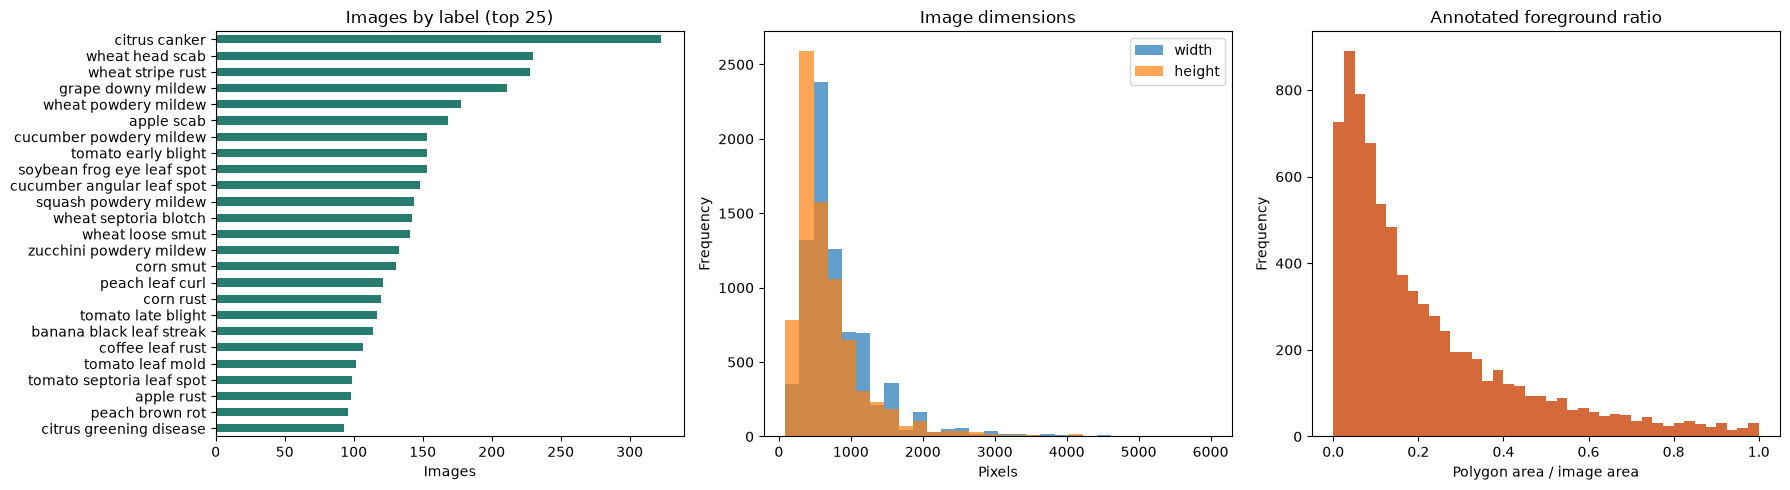

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
label_table['image_count'].head(25).sort_values().plot.barh(ax=axes[0], color='#287c6f', title='Images by label (top 25)')
axes[0].set_xlabel('Images')
df[['width', 'height']].plot.hist(alpha=0.7, bins=30, ax=axes[1], title='Image dimensions')
axes[1].set_xlabel('Pixels')
df['foreground_ratio'].plot.hist(bins=40, ax=axes[2], color='#d46a3a', title='Annotated foreground ratio')
axes[2].set_xlabel('Polygon area / image area')
plt.tight_layout()


## 4. Visual inspection: image and annotation overlays

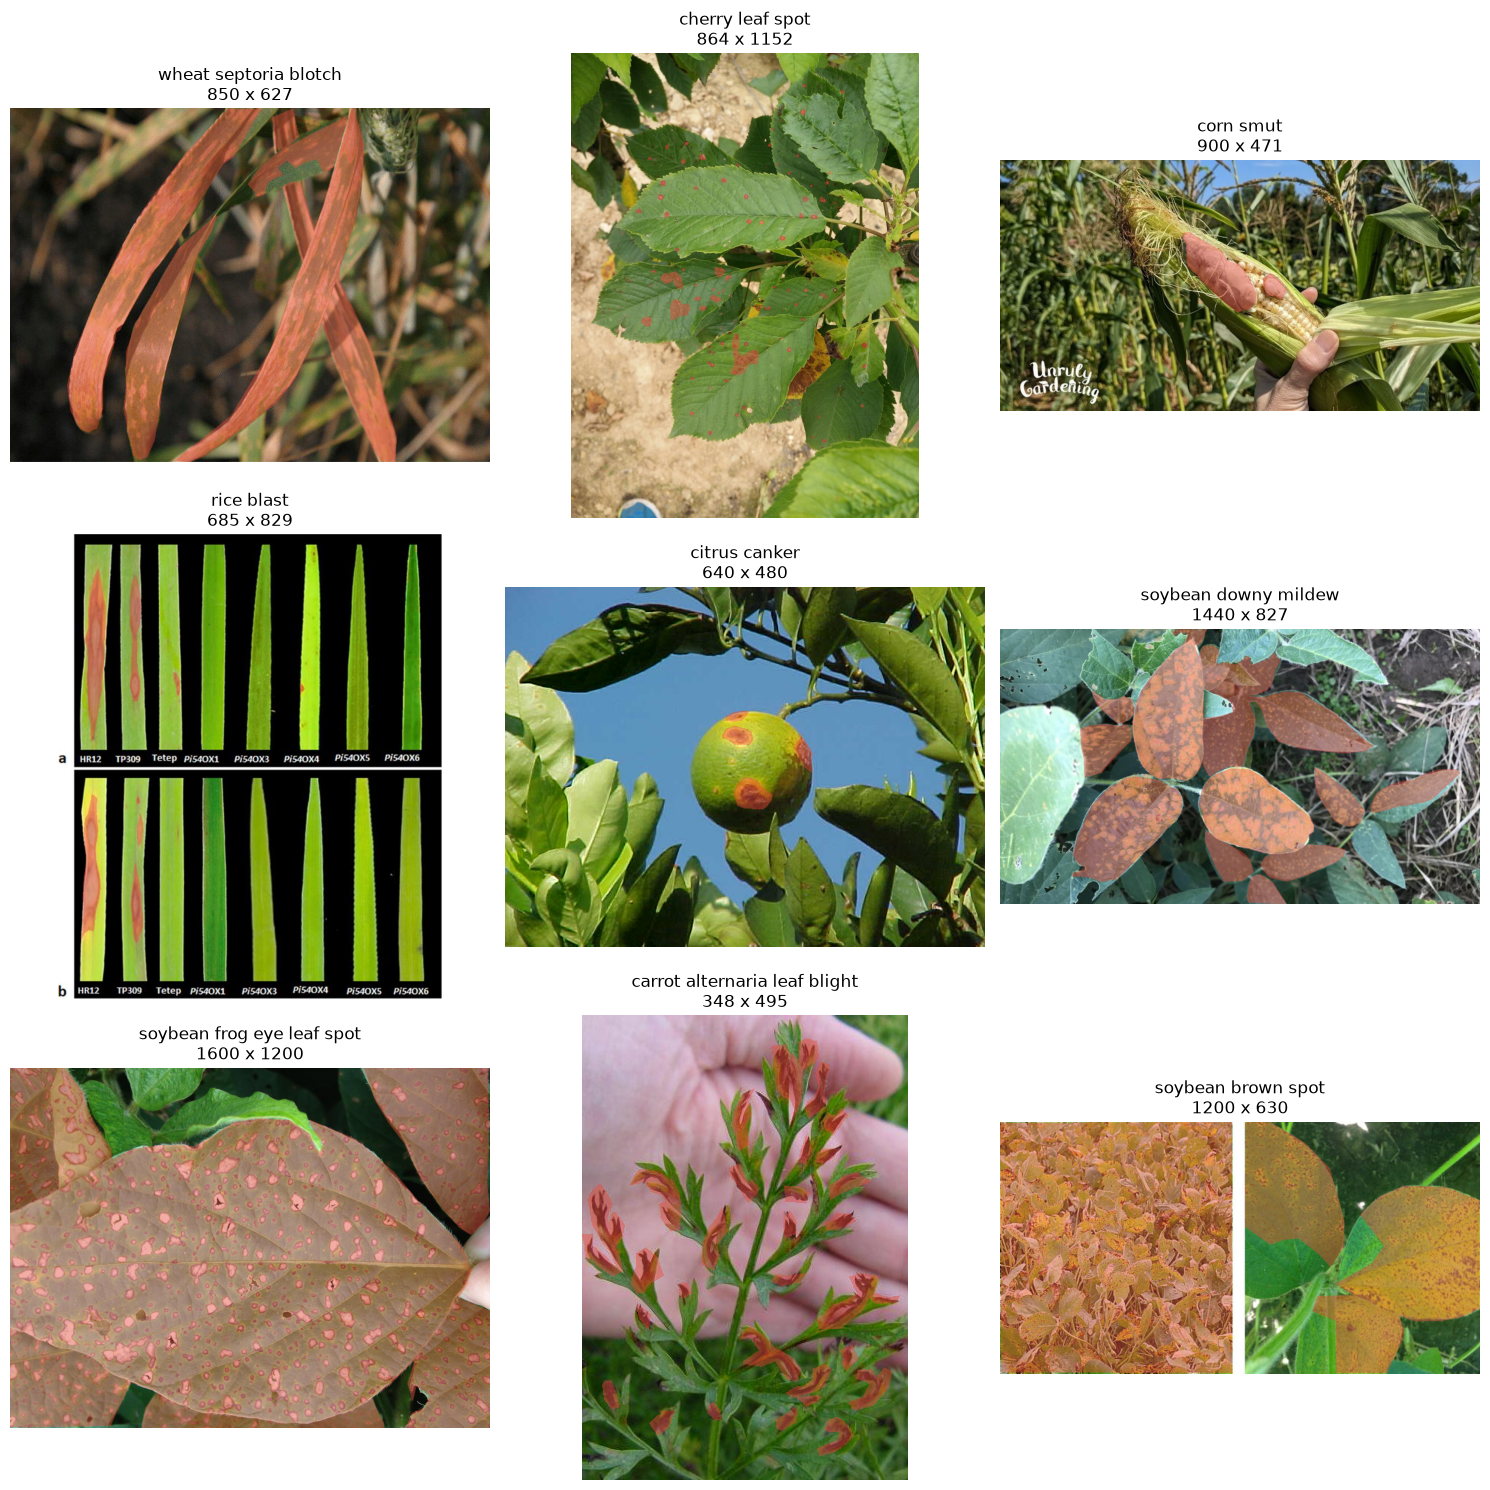

In [8]:
def overlay_image(row):
    image = Image.open(row['image_path']).convert('RGB')
    mask = Image.open(row['annotation_path']).convert('L').resize(image.size)
    image_array = np.asarray(image).copy()
    mask_array = np.asarray(mask) > 0
    image_array[mask_array] = (0.55 * image_array[mask_array] + 0.45 * np.array([231, 76, 60])).astype(np.uint8)
    return image_array

sample = df[df['polygon_count'] > 0].sample(min(9, (df['polygon_count'] > 0).sum()), random_state=42)
fig, axes = plt.subplots(math.ceil(len(sample) / 3), 3, figsize=(15, 5 * math.ceil(len(sample) / 3)))
axes = np.atleast_1d(axes).ravel()
for axis, (_, row) in zip(axes, sample.iterrows()):
    axis.imshow(overlay_image(row))
    axis.set_title(f"{row['labels_display']}\n{row['width']} x {row['height']}")
    axis.axis('off')
for axis in axes[len(sample):]:
    axis.axis('off')
plt.tight_layout()

## 5. Findings and follow-up checks

The cells above provide the empirical summary once the local archive is available. Before training, use the results to check: (1) whether every image has a valid annotation, (2) whether labels are severely imbalanced, (3) whether masks are implausibly tiny or nearly full-frame, (4) whether image dimensions require a consistent resize policy, and (5) whether the visual overlays match the intended diseased regions.

This EDA does not infer crop or disease mappings from the project classification taxonomy. PlantSeg has its own segmentation labels, so label harmonization should be a separate, reviewed step. Polygon areas are geometric estimates and may overlap; overlapping polygons can therefore make the summed foreground ratio an upper bound rather than an exact pixel-union measurement.